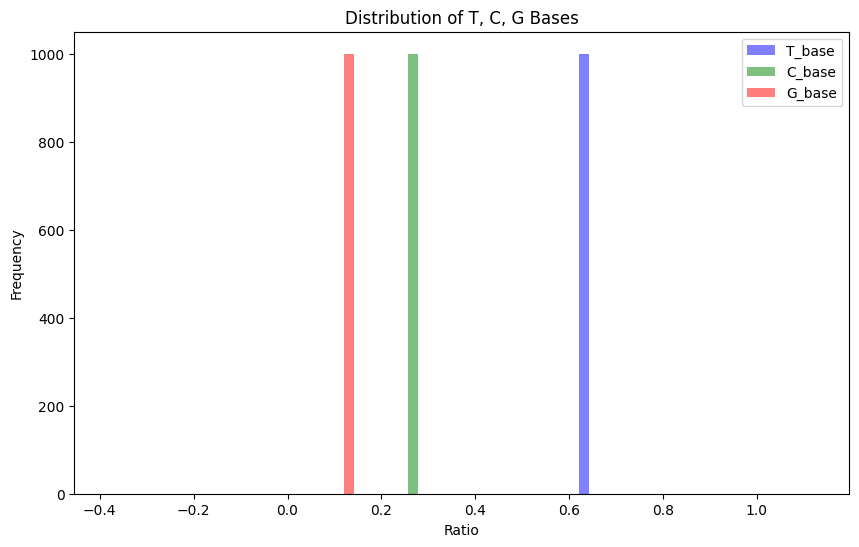

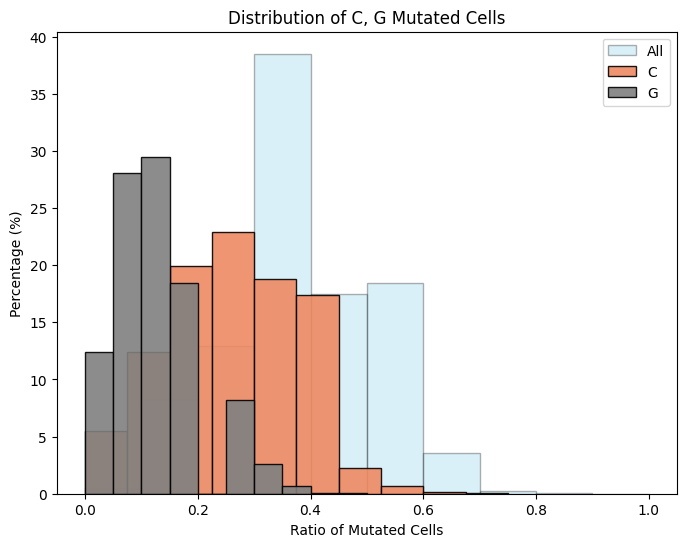

In [19]:
# import
from src.py_utils import *
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages

random.seed(2)

resampleNum = 1000
refBase = "T"
#baseQualityInfoOnesite = "||30|||;||30|||;||30|||;|22||||;|41||||;|41||||;|41||||;||37|||;|37||||;|41||||;|41||||;|||30||"
baseQualityInfoOnesite = "||30|||;||30|||;|22||||;|41||||;|41||||;|41||||;|37||||;|||30||"

readcountsNum, baseWeight, tmpDic, tmpDicP, readcountsWeight = shuffle_reads_features(refBase,baseQualityInfoOnesite)

samples_random_baseQuaInfo = []
for i in range(0, resampleNum):
    sample_random_baseQuaInfo_tmp = shuffle_reads_baseonFeatures(readcountsNum, baseWeight, tmpDic, tmpDicP, readcountsWeight)
    samples_random_baseQuaInfo.append(sample_random_baseQuaInfo_tmp)

def get_cellMut_type(cellbaseQualityInfo, refBase):
    # |22|30|||
    cellInfoSets = cellbaseQualityInfo.split("|")
    baseRes = [BASIC_BASE[cellInfoSets.index(i)] for i in cellInfoSets if i != ""]
    baseRes = [base for base in baseRes if base != refBase]
    return baseRes

def count_oneSite_mutType(baseQualityInfoOnesiteList, refBase):
    res_MutType = {"A": 0, "T": 0, "C": 0, "G": 0, "D": 0, "I": 0}
    for baseQualityInfoOnesite in baseQualityInfoOnesiteList:
        onecellMutType = get_cellMut_type(baseQualityInfoOnesite, refBase)
        if onecellMutType == []:
            res_MutType[refBase] += 1
        else:
            for base in onecellMutType:
                res_MutType[base] += 1
    return res_MutType

T_base = []
C_base = []
G_base = []

for i in range(0, resampleNum):
    tmpType = count_oneSite_mutType(samples_random_baseQuaInfo, refBase)
    total = sum(tmpType.values())
    ratios = {key: value / total for key, value in tmpType.items()}
    T_base.append(ratios["T"])
    C_base.append(ratios["C"])
    G_base.append(ratios["G"])


plt.figure(figsize=(10, 6))
plt.hist(T_base, bins=50, alpha=0.5, label='T_base', color='blue')
plt.hist(C_base, bins=50, alpha=0.5, label='C_base', color='green')
plt.hist(G_base, bins=50, alpha=0.5, label='G_base', color='red')
plt.xlabel('Ratio')
plt.ylabel('Frequency')
plt.title('Distribution of T, C, G Bases')
plt.legend()
plt.show()

refNum, altNum = count_CellNum_fromQuainfo(refBase, baseQualityInfoOnesite)
totalCell = refNum + altNum

mutRateList = []
mutRateList_C = []
mutRateList_G = []



for i in range(0, resampleNum * 50):
    oneSiteBaseQuaList = random.sample(samples_random_baseQuaInfo, totalCell * 2)
    tmpType = count_oneSite_mutType(oneSiteBaseQuaList, refBase)
    total_cell = sum(tmpType.values())
    c_cell = tmpType["C"]/total_cell
    g_cell = tmpType["G"]/total_cell
    mutRateList_C.append(c_cell)
    mutRateList_G.append(g_cell)
    oneSiteBaseQua = ";".join(oneSiteBaseQuaList)
    refNum_tmp, altNum_tmp = count_CellNum_fromQuainfo(refBase, oneSiteBaseQua)
    total_tmp = refNum_tmp + altNum_tmp
    mutRate = altNum_tmp / total_tmp
    mutRateList.append(mutRate)


plt.figure(figsize=(8, 6))

weights = np.ones_like(mutRateList) * 100. / len(mutRateList)
weights_C = np.ones_like(mutRateList_C) * 100. / len(mutRateList_C)
weights_G = np.ones_like(mutRateList_G) * 100. / len(mutRateList_G)


plt.hist(mutRateList, bins=10, color='skyblue', edgecolor='black', alpha=0.3, label='All', weights=weights)
plt.hist(mutRateList_C, bins=10, color='#EF8A62', edgecolor='black', alpha = 0.9,label='C', weights=weights_C)
plt.hist(mutRateList_G, bins=10, color='#808080', edgecolor='black', alpha = 0.9, label='G', weights=weights_G)


plt.xlabel('Ratio of Mutated Cells')
plt.ylabel('Percentage (%)')
plt.title('Distribution of C, G Mutated Cells')
plt.legend()

plt.show()

# Save the plots to a PDF
with PdfPages('/Users/liqun/Desktop/scMutraceReproducibility/Figure1/scMutrace_perfermance_mutNoise_distribution.pdf') as pdf:
    # First plot
    #plt.figure(figsize=(10, 6))
    #plt.hist(T_base, bins=50, alpha=0.5, label='T_base', color='blue')
    #plt.hist(C_base, bins=50, alpha=0.5, label='C_base', color='green')
    #plt.hist(G_base, bins=50, alpha=0.5, label='G_base', color='red')
    #plt.xlabel('Ratio')
    #plt.ylabel('Frequency')
    #plt.title('Distribution of T, C, G Bases')
    #plt.legend()
    #pdf.savefig()
    #plt.close()

    # Second plot
    plt.figure(figsize=(8, 6))
    #plt.hist(mutRateList, bins=10, color='skyblue', edgecolor='black', alpha=0.3, label='All', weights=weights)
    plt.hist(mutRateList_C, bins=10, color='#EF8A62', edgecolor='black', alpha = 0.9,label='C', weights=weights_C)
    plt.hist(mutRateList_G, bins=10, color='#808080', edgecolor='black', alpha = 0.9, label='G', weights=weights_G)
    plt.xlabel('Ratio of Mutated Cells')
    plt.ylabel('Percentage (%)')
    plt.title('Distribution of C, G Mutated Cells')
    plt.legend()
    pdf.savefig()
    plt.close()

In [3]:
import os
import re
import timeit
import argparse
import numpy as np
from scipy.stats import beta
from scipy.optimize import fmin
from src.py_utils import *

def fit_using_moment(data):
    mean=np.mean(data)
    var=np.var(data,ddof=1)
    alpha=mean**2*(1-mean)/var-mean
    beta=alpha*(1-mean)/mean
    return alpha, beta

def generate_success_trailArray_Q(randomExtractSNPPath):
    successesSingleCellList = []
    trialsSingleCellList = []
    successesCellNumList = []
    trialsCellNumList = []
    successesSiteList = []
    trialsSiteList = []
    with open(randomExtractSNPPath, "r") as f:
        for line in f:
            lineSets = line.split("\t")
            successesSingleCellTmp = int(lineSets[5])
            trialsSingleCellTmp = int(lineSets[3])
            successesCellNumTmp = int(lineSets[8])
            trialsCellNumTmp = int(lineSets[6])
            if trialsCellNumTmp < 3:
                continue
            successesSingleCellList.append(successesSingleCellTmp)
            trialsSingleCellList.append(trialsSingleCellTmp)
            successesCellNumList.append(successesCellNumTmp)
            trialsCellNumList.append(trialsCellNumTmp)
    f.close()
    successesCellArray = np.array(successesSingleCellList)
    trialsCellArray = np.array(trialsSingleCellList)
    successesCellNArray = np.array(successesCellNumList)
    trialsCellNArray = np.array(trialsCellNumList)
    return successesCellArray, trialsCellArray, successesCellNArray, trialsCellNArray

c, d, e, f = generate_success_trailArray_Q("/Users/liqun/scMutraceProject/Data/GSE144240/data/RandomVCF/Mut/P10_cSCC/random_vcf.vcf")

data_altCellNumFreOneSite = c/d
data_altReadsFreOneSite = e/f
#----------------Fit using moments----------------
#alpha_data1, beta_data1 = fit_using_moment(data_altReadsFreOneCell)
alpha_data2, beta_data2 = fit_using_moment(data_altCellNumFreOneSite)
alpha_data3, beta_data3 = fit_using_moment(data_altReadsFreOneSite)

print("#############################################")
print ('# alpha, beta from moments [altCellNumFreOneSite]:',alpha_data2, beta_data2)
print ('# alpha,beta from moments [altReadsFreOneSite]:',alpha_data3, beta_data3)

#############################################
# alpha, beta from moments [altCellNumFreOneSite]: 0.5336839955129021 0.7802700360022083
# alpha,beta from moments [altReadsFreOneSite]: 0.4892520698405911 0.7612385316204912


In [6]:
data_altCellNumFreOneSite

array([0.25      , 0.07142857, 0.22222222, ..., 0.5       , 0.66666667,
       0.10526316])

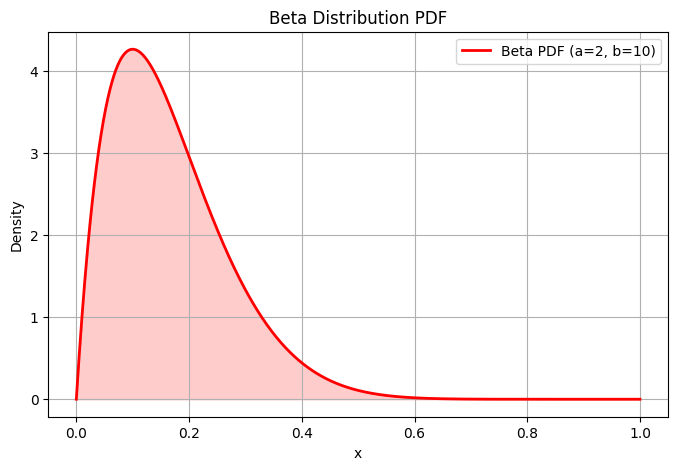

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

# 定义 Beta 分布的参数
a, b = 2, 10

# 定义 x 范围
x = np.linspace(0, 1, 1000)
# 计算 PDF
pdf = beta.pdf(x, a, b)

# 绘制图形
plt.figure(figsize=(8, 5))
plt.plot(x, pdf, 'r-', lw=2, label=f'Beta PDF (a={a}, b={b})')
plt.fill_between(x, pdf, alpha=0.2, color='red')
plt.title('Beta Distribution PDF')
plt.xlabel('x')
plt.ylabel('Density')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

# 定义 Beta 分布的参数
a, b = alpha_data3, beta_data3

# 定义 x 范围
x = e

# 计算 PDF
pdf = beta.pdf(x, a, b)

# 绘制图形
plt.figure(figsize=(8, 5))
plt.plot(x, pdf, 'r-', lw=2, label=f'Beta PDF (a={a}, b={b})')
plt.fill_between(x, pdf, alpha=0.2, color='red')
plt.title('Beta Distribution PDF')
plt.xlabel('x')
plt.ylabel('Density')
plt.legend()
plt.grid(True)
plt.show()

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta, kstest

# 假设你的数据是 data
data = data_altCellNumFreOneSite

# 拟合 Beta 分布
a, b, loc, scale = beta.fit(data)

print(f'拟合参数：a={a}, b={b}, loc={loc}, scale={scale}')



/Users/liqun/anaconda3/envs/singleCell/lib/python3.10/site-packages/scipy/stats/_continuous_distns.py:795: RuntimeWarning: invalid value encountered in sqrt
  sk = 2*(b-a)*np.sqrt(a + b + 1) / (a + b + 2) / np.sqrt(a*b)


拟合参数：a=0.8593329756200498, b=0.6179217208733041, loc=-0.0034485681515703933, scale=1.0034485681515706


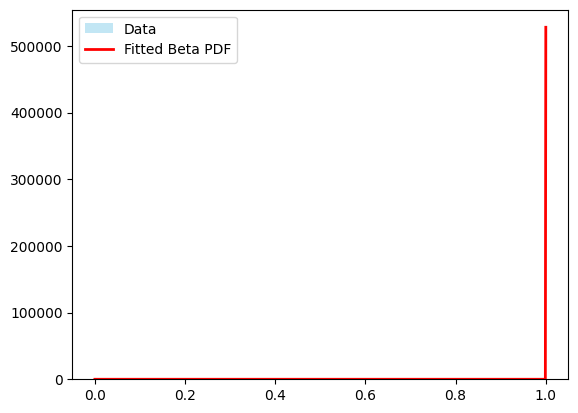

In [17]:
x = np.linspace(0, 1, 1000)
pdf_fitted = beta.pdf(x, a, b, loc=loc, scale=scale)

plt.hist(data, bins=20, density=True, alpha=0.5, color='skyblue', label='Data')
plt.plot(x, pdf_fitted, 'r-', lw=2, label='Fitted Beta PDF')
plt.legend()
plt.show()

In [18]:
D, p_value = kstest(data, 'beta', args=(a, b, loc, scale))
print(f'K-S检验 D值={D}, p值={p_value}')

K-S检验 D值=0.30740016441427587, p值=0.0


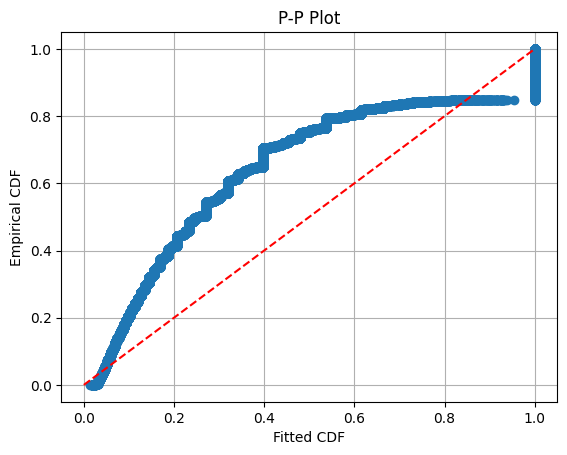

In [19]:
from scipy.stats import probplot

# P-P plot
sorted_data = np.sort(data)
cdf_fitted = beta.cdf(sorted_data, a, b, loc=loc, scale=scale)

plt.plot(cdf_fitted, np.linspace(0,1,len(data)), 'o')
plt.plot([0,1],[0,1],'r--')
plt.xlabel('Fitted CDF')
plt.ylabel('Empirical CDF')
plt.title('P-P Plot')
plt.grid(True)
plt.show()